<a href="https://colab.research.google.com/github/eliot-maisonneuve/collaborative_github_exercise/blob/master/assignment_map25elm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COM4509 / COM6509 Assignment 2026-27

Hello, this is the programming assignment for *Machine Learning and Adaptive Intelligence*. This is worth 50% of the module grade, the remaining 50% will be assessed via the formal exam.

**Deadline: 15th December 2026, 15:00**

Please submit well before the deadline as there may be delays in the submission. Submission will be via Blackboard.

There are 2 parts to this assignment, covering different portions of the course. Both parts are worth 50 marks to give a combined total of 100 marks.

The assessment criteria / mark scheme/breakdown are provided in each part, and more detail on the Marking Criteria is available in [this spreadsheet](https://docs.google.com/spreadsheets/d/1eor2exf0q-onlxJ1EJH-zXe6YRcK5YNRbH-QOwfZY88/edit?usp=sharing) (also linked via Blackboard).

## Use of unfair means and Generative AI

For this assignment **you must not use code/text produced by generative AI**. You are allowed to use AI tools to help you understand the concepts and to help you debug your code, but you must write the code yourself. You are also not allowed to use AI tools to generate text. You must write the text in the coursework yourself.

This is an individual assignment, while you may discuss this with your classmates, **please make sure you submit your own code**. You are allowed to use code from the labs as a basis of your submission.

The university's policy on the use of GenAI is on [this page](https://www.sheffield.ac.uk/study-skills/digital/generative-ai/assessment).

"Any form of unfair means is treated as a serious academic offence and action may be taken under the Discipline Regulations." (from the students Handbook).

## Assignment help

If you are stuck and unsure what you need to do then please ask either in the lectures, labs or on the discussion board. There is a limit to what help we can provide but where possible we will give general guidance with how to proceed.

We are happy for you to discuss the assignment with other students but your code and test answers **must** be your own.

## What to submit

- You need to submit a **pdf** of your notebook *and* the **notebook**. Please name them:

```
assignment_[username].ipynb
assignment_[username].pdf
```
replacing `[username]` with your username, e.g. `abc18de`.

- **Please execute the cells before your submission**, so we can see the results in the pdf. The best way to get a pdf is using Jupyter Notebook locally but if you are using Google Colab and are unable to download it to use Jupyter then you can use the Google Colab *file $\rightarrow$ print* to get a pdf copy.
- **Please do not upload** the data files used in this Notebook. We just want the python notebook *and the pdf*.

## Late submissions

We follow the university's [guidelines on late submissions](https://students.sheffield.ac.uk/assessment/late-submission#coursework).




# Part 1: Linear Regression

## The Dataset

The Sheffield Machine Learning research group is developing approaches to track bees flying through the city. We do this by attaching a tag to the bee which records the (hashed) ids of bluetooth devices it flies near.

We separately cycle around the city, recording the locations of bluetooth devices using a GPS. We can then use this information to tell us roughly the path the bee took on its flight.

The tag also records the direction the bee is flying using an onboard magnetometer.

You are provided with a synthetic dataset. Each item in the `dataset` list is a dictionary, and contains:

- `'path'`: an Nx3 array describing the true flight of the bee. Each row contains the time (in seconds) and the x and the y coordinates (in metres) of the bee. For example:
         
```
        time    x      y
       [  0,   0.6,   7.1 ]
       [  1,   1.3,  14.0 ]
       [  2,   2.1,  20.2 ]
       [  3,   2.8,  26.5 ]
       [  4,   3.7,  33.2 ]
             ...etc...
```

- `'device_locations'`: a dictionary (the keys are the hashed bluetooth device ids). Each item in the dictionary contains the location of that device. For example:
```
 id          x         y
{ 78: array([-984.0, -138.5]),
 210: array([ 786.3,  809.6]),
 406: array([ 472.5, -638.4]),
         ...etc...
```

- `'records'`: an array of the time (in seconds) and id of devices the bee detected. For example:
```
        time  id
      [[ 18, 510],
       [ 19, 510],
       [ 21, 510],
       [ 22, 326],
       [ 22, 510],
       [ 24, 510],
       [ 25, 510],
       [ 45, 950],
       [ 47, 950],

Here the bee detected device 510 at seconds 18, 19, 21,
22, 24 and 25. It detected device 326 at second 22, and
it detected device 950 at seconds 45 and 47. This tells
you which devices it was near to, and so you can then
look up the device locations in the 'device_locations'
dictionary to see where the bee was.
```

- `'directions'`: This has a record of the direction the bee was flying (using an onboard magnetometer). It is an array, with columns recording: the time (in seconds) and a unit x,y vector, pointing in the direction it was flying in. This is only collected occasionally (as the magnetometer uses a lot of power). For example:
```
                 unit vector
        time      x      y
      [[  0. ,   0.9,   0.5],
       [ 20. ,   0.8,   0.5],
       [ 40. ,   0.1,  -1. ],
       [ 60. ,  -0.1,  -1. ],
       [ 80. ,   0.6,  -0.8],
              ...etc...
```       



## The Challenge

You are required to write a function that takes as input:
- `device_locations` - where the bluetooth devices are
- `records` - the device ids seen by the bee
- `directions` - the direction the bee was heading
- `test_times` - times we want predictions for

and returns an `Nx2` array of the bee's locations at the `test_times` given.

So to be clear, the regression will take as input, a vector of $N$ time values, and output an $N \times 2$ matrix of coordinates.

Here's the method you will need to implement. You will almost certainly want to write additional functions, for example to compute predictions from parameters, an objective (cost) function, and to optimise the parameters in your model.

```
def predict_path(device_locations,records,directions,test_times):
    # your code here
  return pred_path #return an Nx2 numpy array
```

**Please keep the method name, parameters and return value the same -- I will be testing your methods on held out test data to see how well they do, and so will need the method's arguments to match.**

## Allowed libraries for Part 1

For this part we are looking for you to demonstrate what you have learned in this module and so we will be restricting what libraries you can use to

    Numpy
    Matplotlib (or similar for plotting)
    JAX and optax


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
import jax
import optax

## Solving the Problem

### Use Linear Regression with a Gaussian Basis

I want you to use **linear regression** to solve this problem. You will need to predict the x-coordinates and y-coordinates as functions of time. I would suggest a Gaussian 'Radial Basis Function' basis set would be suitable. You will probably want to write a function, such as:

```def compute_path(params, times):```

which takes a vector of parameters (i.e. the weights we are multiplying by each basis function) and the times you want to make the predictions for, and returns an `Nx2` array with the x,y coordinates at those times in each row. To handle the x- and y- columns, you might want to use the first half of the parameters as weights for the x's and the second half of the parameters as weights for the y's. For example, the prediction at time t, using parameters $w_1, w_2, ..., w_k$ would equal:

$$x = \sum_{i=1}^{k/2} w_i\;e^{-(t-c_i)^2/2l^2}$$
$$y = \sum_{i=1}^{k/2} w_{i+k/2}\;e^{-(t-c_i)^2/2l^2}$$

$c_i$ are the times that each of the Gaussian RBF basis functions are centred on (probably evenly spaced over the 300s of the dataset, e.g. if we've 14 parameters then $\mathbf{c} = [0,50,100,150,200,250,300]$).

You will need to think about how wide the Gaussian bases are (controlled by $l$ in the equation) and how many there are ($k$).

### Objective Function

You then need to write an objective (or 'cost' function). For example:

```def objective(params, device_locs, records, directions):```

Things you'll need this function to do:
1) Compute the path using the `compute_path` function you wrote above.
2) Compute how badly it is fitting the observations in `records`. For example you could call `compute_path` above with the times in records[:, 0], to get the location where the model thinks the bee was when it saw each device, and compare that predicted location to where each device actually is. You might then sum up the squares of these errors (you'll need to use jax's numpy functions for all this by the way, so we can autodiff it later).
3) You'll need to return a single value describing how badly the data fits.

(again: don't forget to use jnp functions in the objective so we can autograd it later!).

### Optimising

Maybe inside the `predict_path` method, you will need to:

- initialise your parameters (e.g. randomly?)
- optimise them (minimising the objective function)
- return the path predicted by them

See [this demo](https://colab.research.google.com/drive/10dLDGLxSdn_Ll6fwSegwdqC4SHAOCdcu?usp=sharing) which demonstrates how to write a prediction method, an objective function and then how to optimise using JAX and optax.

### Direction

Once you've got a reasonable path being predicted, have a think how you might compute predicted directions the bee is flying in, and how those might be compared to the values in `directions`. Add this into your cost function - does it help improve the predicted path?

### Choosing hyperparameters and regularising

Once you have your basic model working, you'll need to:

- Select hyperparameters (for example the number and width of the basis functions, and other parameters, e.g. if you want to control how much regularisation you have etc). The true path is available for each item in dataset in the `'path'` item, so you can evaluate how well your model did. Do you need to do a training/validation split in this case? **This code won't necessarily be called by the `predict_path` method. I've added another cell for you to add any separate code you wrote to optimise the hyperparameters.**
- You might want to limit the speed the bee can fly or accelerate in your model, so you might want to consider regularising.
- You might also want to consider running multiple restarts for your optimiser.
- There are other improvements you could make.



## Notes and Tips

### Please use linear regression

Obviously a lot of other methods exist. For example, a particle smoother or other Bayesian approach might be more appropriate, and some of you may be familiar with these methods, but as they were not covered in this module I want you to focus on using linear regression for this question.

### Step by Step how you might go about this coursework

**Explore the data...**

Before you start coding the actual answer, you might find it useful to just plot and explore the dataset a little.

Have a look maybe at the first flight in the dataset; and just look at what's inside each part - maybe try plotting parts of these yourself:

- `dataset[0]['device_locations']`
- `dataset[0]['records']`
- `dataset[0]['directions']`
- `dataset[0]['path']`

**Coding the model...**

You'll probably find this problem easier to solve if you start with just a small number of parameters (e.g. 8).

- Start by picking parameters randomly.
- Write a `compute_path` function to generate predictions for x and y coordinates from the parameters.
- Next, just focus on the records (and device locations): use your `compute_path` method to predict the location of the bee at the time for each row in `records`, you can use this to then compare to the device's true location.
- Compute a single 'error' value for how far the bee was from all the devices.
- Wrap this inside an objective function
- Use the example optimisation code with the objective function to get a good guess for the parameters.
- You should be able to get a roughly ok path, that passes the devices detected (but will obviously deviate at those times we don't have observations).
- You then can try incorporating the direction observations (adding to the total cost inside the objective function - you could for example compute a unit vector of the bee's velocity at the times a direction was observed (i.e. those values in `directions[:,0]`), and compare it to the vectors in `directions[:,1:]`. (you might need to think of how to get the direction of the bee's flight from a series of locations).
- Later work on optimising your hyperparameters, and other improvements.

## Download the Dataset

In [2]:
import urllib

urllib.request.urlretrieve('https://drive.usercontent.google.com/download?id=1Pygm6bGvBBfBlxXat0YnKDvieEmWdXWA&export=download','dataset.npy')
dataset = np.load('dataset.npy',allow_pickle=True)

In [3]:
#Helper function to plot your results

def plot_results(data, pred_path):
  """
  Plots the true path and the predicted path. It includes the locations of the
  bluetooth devices, and adds crosses onto those that have been detected by the
  bee. It also includes vectors along the predicted path, with the direction
  information in.
  """

  plt.plot(data['path'][:,1],data['path'][:,2],':r',label='true path')
  plt.plot(data['path'][0,1],data['path'][0,2],'or',label='true start')
  plt.plot(pred_path[:,0],pred_path[:,1],'-',label='predicted path')
  plt.plot(pred_path[0,0],pred_path[0,1],'ok',label='predicted start')

  for dev_id, dev in data['device_locations'].items():
    plt.plot(dev[0],dev[1],'.')
  for i,rec in enumerate(data['records']):
    dev = data['device_locations'][rec[1]]
    plt.plot(dev[0],dev[1],'kx',markersize=10,label=None if i>0 else 'detected device')

  for d in data['directions']:
    p = pred_path[int(d[0]),:]
    plt.plot([p[0],p[0]+d[1]*250],[p[1],p[1]+d[2]*250],'r-',alpha=0.2)

  plt.legend()

## Assessment Criteria for Part 1

### How we assess the work

Marks will be decided through:
- the results of your model (in Section 1.1) tested by running your `predict_path` method against an unseen dataset (this will be drawn from the same synthetic data as the provided training dataset).
- partly on inspecting your code and comments (we'll be looking for efficient, wise approaches to implementation, and appropriately documented code, for top marks).
- partly on the answers given in Section 1.2 (to show you can communicate your design decisions and understanding).

### The mark scheme breakdown

The following describes the mark scheme:

**20 marks:** successfully implementing the basic linear regression solution, i.e. using just the device IDs. *(evaluated through model test results and code inspection)*.

**10 marks:** successfully incorporating the `direction` data into your model *(evaluated through model test results, code inspection and your answer to Q1, in Section 1.2)*.

**20 marks:** successfully implementing hyperparameter optimisation, regularisation, random-restarts, and other improvements beyond the basic regression model, to a **maximum of three improvements**. These need to each be explained in your answer to Q2. (evaluated through model test results, code inspection and your answer to Q2, in Section 1.2).

See the [Marking Criteria spreadsheet](https://docs.google.com/spreadsheets/d/1eor2exf0q-onlxJ1EJH-zXe6YRcK5YNRbH-QOwfZY88/edit?usp=sharing) for more detail.

Note: The evaluation against the unseen test data will check your model is working reasonably well - but your model will never get the answer exactly! So, once it is working (i.e. using the observations correctly, and with suitably optimised hyperparameters etc) you are done.

As an illustration, this is the results of an attempted solution, applied to the first dataset item (I've not yet optimised the hyperparameters, so it could be improved a little).

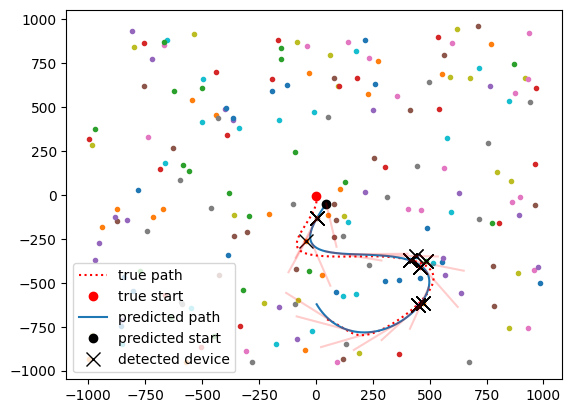

## Section 1.1.

Implement your code below, by replacing the code in the `predict_path` method (feel free to add additional methods that you might find useful, for computing the objective etc). Remember that the `predict_path` arguments and return output should remain in the same format.



In [23]:
def compute_path(params, times):
    # weights are split between x and y
    n_params = len(params)
    w_x = params[:n_params//2]
    w_y = params[n_params//2:]
    # centres of gaussian functions
    n_centres = n_params // 2
    t_min = dataset[0]['path'][0,0]
    t_max = dataset[0]['path'][-1,0]
    centres = np.linspace(t_min, t_max, n_centres)
    l = t_max / n_centres
    # gaussian basis function
    Phi = jnp.exp(-0.5 * (((times[:, None]-centres)**2) / (l ** 2)))
    # predict x and y from weighted basis functions
    x_pred = jnp.dot(Phi, w_x)
    y_pred = jnp.dot(Phi, w_y)
    # return coordinates
    return jnp.column_stack((x_pred, y_pred))

def objective(params, device_locations, records, directions):
    record_times = records[:, 0]
    target_locations = jnp.array([device_locations[int(dev_id)] for dev_id in records[:, 1]])
    predictions = compute_path(params, record_times)
    path_sse = jnp.sum((predictions - target_locations)**2)
    path_sae = jnp.sum(jnp.abs(predictions - target_locations))

    # reglularisaion
    # find direction as a unit vector from components of velocity
    dir_times = directions[:, 0]
    delta = 0.1
    locs_t = compute_path(params, dir_times)
    locs_t_plus_dt = compute_path(params, dir_times + delta)
    vel = (locs_t_plus_dt - locs_t) / delta

    # normalise to unit vectors
    mag_vel = (vel[:, 0]**2 + vel[:, 1]**2)**0.5
    pred_directions = vel / (mag_vel[:, None] + 1e-9)

    # compare against the true x, y components
    true_directions = directions[:, 1:]
    direction_sae = jnp.sum(jnp.abs(pred_directions - true_directions))
    direction_sse = jnp.sum((pred_directions - true_directions)**2)

    # Sample times evenly across the whole flight to measure speed
    t_eval = jnp.linspace(0, 300, 100)
    dt = 1
    loc_now = compute_path(params, t_eval)
    loc_next = compute_path(params, t_eval + dt)
    velocities = (loc_next - loc_now) / dt

    # Penalise high speeds (Velocity L2 Regularisation)
    vel_sse = jnp.sum(velocities**2)

    # weigths regularisation
    L1 = sum(params)
    L2 = sum(params**2)

    # regularisation scaling terms
    lambda_vel = 0
    lambda_directions = 0
    lambda1 = 0
    lambda2 = 0.01


    cost = path_sse + lambda_vel*vel_sse + lambda_directions*direction_sse + lambda1*L1 + lambda2*L2

    return cost

def predict_path(device_locations, records, directions, test_times):
    """
    For the given dictionary of device_locations, the array of detections
    detect by the bee's tag (recorded in 'records'), and the 'directions'
    the bee was flying at specific times, predict the location of the bee
    at 'test_times', returning an Nx2 array of the predicted locations.
    """
    # number of parameters
    k = 16*2
    params = np.random.randn(k)

    # optimiser
    learning_rate = 0.5
    optimiser = optax.adam(learning_rate)
    opt_state = optimiser.init(params)

    # optimisation loop
    num_iterations = 500
    for i in range(num_iterations):
        loss, grads = jax.value_and_grad(objective)(params, device_locations, records, directions)
        updates, opt_state = optimiser.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        if i%100 == 0:
          print(f'loss: {loss}')
    pred_path = compute_path(params, test_times)
    return pred_path


In [5]:
print(dataset[0]['path'][0,0])
print(dataset[0]['path'][-1,0])

0.0
299.0


loss: 14414127.0
loss: 8342287.5
loss: 4557235.5
loss: 2357723.25
loss: 1174064.0


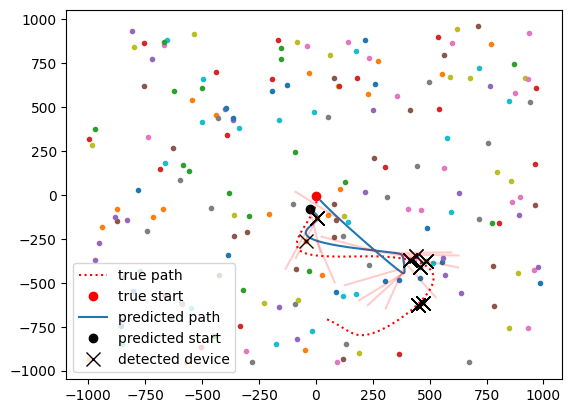

In [24]:
# feel free to delete this cell, here we are just generating the predicted path,
# and plotting it, for the first item in dataset.

pred_path = predict_path(dataset[0]['device_locations'],dataset[0]['records'],dataset[0]['directions'],dataset[0]['path'][:,0])
plot_results(dataset[0], pred_path)

In [7]:
# Hyperparameter optimisation code
# write any code you used to optimise hyperparameters etc, here.

# regularisation terms
# weights regularisation terms
# lamda vel
# lamb directions
# number of epochs
# number of basis functions
# width of basis functions


## Section 1.2.

Please write, in the cells provided, text-only answers to the following two questions.

### Question 1 [**maximum 100 words**]

Explain how you computed the objective/cost/error value of the predicted path with respect to the `direction` observations. If you didn't implement this aspect, explain how you might approach this anyway. [**maximum 100 words, total**].

The velocity componnet ($v_x$, $v_y$) were found from the difference in position at time $t$ and $t+dt$ divided by $dt$:

$v_x = \frac{x_{t+dt} - x_t}{dt}$, $v_y = \frac{y_{t+dt} - y_t}{dt}$.

The velocity vector was divided by its magnitude to find the unit vector, matching the form of the data: $\frac{v_x+v_y}{\sqrt{v_x^2+v_y^2}}$.

The sum of squared errors (SSE) was calculated each time the actual direction was known. This term was added to the objective function with a scaling term to minimise direction error:

 $\lambda_{vel}SSE_{directions}$.

### Question 2 [**maximum 200 words**]

Explain each of the improvements you made to the model beyond the basic linear regression (e.g. hyperparameter optimisation, regularisation, random-restarts). You need to explain (a) how you did it, (b) why you did it, and (c) whether it helped. Add a title, and start a new paragraph for each one, for example:

> **Hyperparameter optimisation**
> I optimised the number of basis functions by trying a grid search...etc...
>
> **Regularisation**
> I regularised the parameters by adding to the objective a...etc...

[**maximum 200 words, total**]

[Write Question 2 answer here]

# Part 2: Neural Networks and Deep Learning

## Overview
In this part of the assignment, you will aim to implement a set of classifier models which will be used to perform activity recognition based on accelerometer data. The dataset that you will be using is the Human Activity Recognition Trondheim (HARTH) dataset contains accelerometer recordings collected during everyday activities. Two sensors, worn on the lower back and thigh, each measure acceleration along three axes, giving six channels sampled at 50 Hz. Background information is available in the [HARTH dataset description](https://archive.ics.uci.edu/dataset/779/harth).

As described below, your task is to implement at least three different classifier models, including at least one baseline model and at least one neural network model (using PyTorch). You will then evaluate the performance of your models and compare them against each other. You will also be expected to discuss the results of your experiments and draw conclusions based on your findings.

The dataset contains both a range of activities that are not equally represented and participants that might have different behaviours to each other. It is important that you focus on building a balanced model that can generalise well to need participants. Your main learning algorithm will focus on the activity classification but you will need to consider the test evaluation across both seen and unseen participants. These concepts should form part of your discussions.

The data has already been pre-processed into a windowed format, where each window contains 50 samples (1 second of data) and is labeled with the corresponding activity. Each window is represented as a 50 x 6 matrix, where each column corresponds to one of the six channels (three axes from each sensor) and each row corresponds to a time step. Since you will be implementing neural network models, you will need to reshape the data into a format suitable for input into a neural network. You will also need to perform some additional preprocessing steps, such as normalizing the data and splitting it into training and testing sets. You may wish to implement a baseline model using a traditional machine learning algorithm (e.g., logistic regression) to compare the performance of your neural network models against. For either case you may wish to use some predefined temporal features (e.g., mean, standard deviation, etc.) extracted from the raw data as input to your models. A function is provided to extract these features but it returns unscaled results. You may also wish to experiment with different neural network architectures (e.g., feedforward, convolutional, recurrent) and hyperparameters (e.g., learning rate, batch size, number of layers) to see how they affect the performance of your models.

This question is divided into 4 parts:
- 2.1: Data exploration and methodology design
- 2.2: Implement and train your models
- 2.3: Plot and evaluate the performance of your models
- 2.4: Discussion of results and conclusions

## Allowed libraries for Part 2

For this part we are looking for you to demonstrate what you have learned in this module and so we will be restricting what libraries you can use to

- Numpy, Scipy and Pandas
- Matplotlib (or similar for plotting)
- PyTorch
- Scikit-Learn (for baseline models)

## Assessment criteria for Part 2

Part 2 will be marked across 5 assessment areas. These and what we are looking for in each area are described in the table below.

| Area | What we are looking for | Marks |
|---|---|---:|
| **Methodology and Experiment Design** | Explains a clearly justified approach to preprocessing, validation and model selection, ensuring fair experiments and avoiding data leakage. | 15 |
| **Model Implementation and Trainign** | Correctly implements and trains at least three distinct classifiers models, documenting training and hyperparameter selection. | 10|
| **Results and Evaluation** | Presents results using appropriate metrics, tables and clear plots, and interprets differences between models, activity classes, and seen and unseen participants. | 10 |
| **Conclusions and Critical Reflection** | Draws conclusions supported by the results, critically examine your decisions and learning, and propose specific improvements that addresses the investigation’s limitations. | 10 |
| **Code Quality and Reproducibility** | Provides readable, organised and appropriately documented code, with sufficient settings and comments to reproduce the work. | 5 |




## 2.1: Data exploration and methodology design

The initial code below loads the data from the provided files. You should first use a dimensionality reduction technique (e.g., PCA, t-SNE) to visualise the data in a 2D space for both the windowed sensor data and the time features data versions.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import urllib

urllib.request.urlretrieve('https://github.com/SheffieldML/COM4509_dataset/raw/refs/heads/main/HARTH_test_data.npz','HARTH_test_data.npz')
urllib.request.urlretrieve('https://github.com/SheffieldML/COM4509_dataset/raw/refs/heads/main/HARTH_training_data.npz','HARTH_training_data.npz')

# You may want to store your files in Google Drive then mount them rather than
# reuploading every time.
#from google.colab import drive
#drive.mount('/content/drive')
#path_to_data = '/content/drive/MyDrive/[path to your assignment folder]'
path_to_data = ''

# This loads the processed HARTH dataset from the provided .npz file.
# The dataset contains the windowed sensor data and the corresponding activity labels.
data = np.load(path_to_data + 'HARTH_training_data.npz',allow_pickle=True)


print(data.files)  # This will print the names of the arrays stored in the .npz file

X_train = data['X']  # The windowed sensor data
y_train = data['y']  # The corresponding activity labels

group_ids = data['group_ids']  # The person IDs for each window


['X', 'class_ids', 'original_class_ids', 'class_names', 'y', 'group_ids', 'sample_ids', 'channel_names', 'sample_rate_hz', 'window_size_samples', 'storage_dtype']


In [9]:
# This function has been provided to allow you to use it with different model
# styles such as logistic regression. You do not need to use it if you would
# prefer to focus on applying a CNN to the windowed sensor data loaded above.

def extract_time_features(windows, batch_size=2048):
    """Convert HARTH windows into 113 unscaled time-domain features.

    Input: (N, 50, 6), sampled at 50 Hz, with channels ordered as
    back_x, back_y, back_z, thigh_x, thigh_y, thigh_z.
    Output: (N, 113) float32 array, in the same sample order.

    Requires NumPy and SciPy only. Each window is processed independently;
    nothing is fitted, and the input is unchanged. Batching limits memory use.
    Calculations use float64 before the final float32 conversion.
    """
    import warnings
    import numpy as np
    from scipy import signal, stats

    result = np.empty((len(windows), 113), dtype=np.float32)
    denoise_b, denoise_a = signal.butter(4, 20, fs=50, btype="lowpass")
    gravity_b, gravity_a = signal.butter(4, 1, fs=50, btype="lowpass")
    pairs = [(i, j) for i in range(6) for j in range(i + 1, 6)] + [(6, 7)]

    for start in range(0, len(windows), batch_size):
        x = windows[start:start + batch_size].astype(np.float64)
        if not np.isfinite(x).all():
            raise ValueError("Windows must contain only finite readings")

        # 1. Remove high-frequency noise; add the magnitude of each sensor.
        x = signal.filtfilt(denoise_b, denoise_a, x, axis=1)
        signals = np.concatenate((x,
            np.linalg.norm(x[:, :, :3], axis=2, keepdims=True),
            np.linalg.norm(x[:, :, 3:], axis=2, keepdims=True)), axis=2)
        gravity = signal.filtfilt(gravity_b, gravity_a, signals, axis=1)
        movement = signals - gravity

        # 2. Eight gravity statistics for each of the eight signals: 64 features.
        mean = gravity.mean(axis=1)
        std = gravity.std(axis=1)
        cv = np.divide(std, mean, out=np.zeros_like(std), where=mean != 0)
        ordered = np.sort(gravity, axis=1)
        # Match the original feature code's sorted-index percentile convention.
        columns = [mean, cv, std]
        columns += [ordered[:, i, :] for i in (0, 12, 25, 37, 49)]

        # 3. Movement skewness, excess kurtosis and energy: 24 features.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Precision loss occurred.*",
                                    category=RuntimeWarning)
            skew = stats.skew(movement, axis=1, bias=True)
            kurtosis = stats.kurtosis(movement, axis=1, fisher=True, bias=True)
        # Skewness/kurtosis are undefined for constant signals; use zero.
        columns += [np.nan_to_num(skew, nan=0.0),
                    np.nan_to_num(kurtosis, nan=0.0),
                    np.sum(movement ** 2, axis=1)]

        # 4. Movement correlations (16) and cross-sensor gravity means (9).
        movement_mean = movement.mean(axis=1)
        movement_std = movement.std(axis=1)
        correlations = []
        for i, j in pairs:
            covariance = ((movement[:, :, i] * movement[:, :, j]).mean(axis=1)
                          - movement_mean[:, i] * movement_mean[:, j])
            correlations.append(covariance / np.maximum(
                movement_std[:, i] * movement_std[:, j], 1e-6))
        columns.append(np.stack(correlations, axis=1))
        columns.append(np.stack([(mean[:, i] + mean[:, j]) / 2
                                 for i in range(3) for j in range(3, 6)], axis=1))

        features = np.concatenate(columns, axis=1).astype(np.float32)
        if not np.isfinite(features).all():
            raise ValueError("Feature calculation produced non-finite values")
        result[start:start + len(x)] = features

    return result

In [10]:
# You may wish to use these temporal features instead of the raw windowed data for your models.
# You can extract the features from the training data as follows:
features = extract_time_features(X_train)

In [11]:
# Use a dimensionality reduction technique to visualise the data and other analysis

Comment on the difference between the visualisations of the two different feature sets, the class distributions and any other relevant points of the data.

Write you answer here.

Now you should discuss the approach that you will use in the following sections. You should explain the following points:
- The models that you will implement below,, including any hyperparameters relevant to each model, and providing a justification for why you have chosen these architectures.
- The training procedures that you will be using, including how you will split the data and select or optimise any hyperparameters.
- You should also describe how you will evaluate the performance of your models, including any metrics that you will be using (e.g accuracy, macro-F1 scores).

Keep your descriptions concise and to the point, but ensure that you provide enough detail to justify your approach.

Write your methodology here.

## 2.2: Implement and train your models

In this section you should implement at least three different classifier models, including at least one baseline model and at least one neural network model. You should also implement any necessary preprocessing steps, such as normalising the data and splitting it into training and testing sets.



Implement your models in the code cells below. You may wish to implement additional helper functions to assist with training and evaluation of your models. You will be assessed on the correctness of your implementations, the performance of your models, and the clarity of your code. You should also include comments in your code to explain what each part of the code is doing.

In [12]:
# Implement you models here. You can use as many code cells as you need
# but you should ensure that your code is well-organized and easy to follow.

## 2.3: Plot and evaluate the performance of your models

You should now evaluate the performance of your models on the test data provided. You should plot the performance of your models using appropriate metrics (e.g., accuracy, or F1 score) and compare the performance of your different models. The test data is split into two sets: one containing data from participants that were seen during training, and one containing data from participants that were not seen during training. You should evaluate the performance of your models on both sets of test data.

At minimum you should:
- Plot the performance of your models on the test data for both seen and unseen participants.
- Plot the confusion matrix for each of your models on the test data for both seen and unseen participants.

In [13]:
test_data = np.load(path_to_data + 'HARTH_test_data.npz')
print(test_data.files)

X_seen_windows = test_data['X_seen_windows']
y_seen = test_data['y_seen']

X_unseen_windows = test_data['X_unseen_windows']
y_unseen = test_data['y_unseen']


['class_ids', 'class_names', 'original_class_ids', 'channel_names', 'sample_rate_hz', 'window_size_samples', 'X_unseen_windows', 'y_unseen', 'sample_ids_unseen', 'group_ids_unseen', 'X_seen_windows', 'y_seen', 'sample_ids_seen', 'group_ids_seen']


In [14]:
# Code your plots here

## 2.4: Discussion of results and conclusions

Write a concise discussion of the results of your experiments, including any insights that you have gained from your analysis and conclusions you can draw from them. This should cover the comparison of the models, their relative performance on the portions of the test set and any other relevant results.

You should also reflect on the success your work by discussing any limitations and suggest possible improvements or future work. Your discussion should be based on the results of your experiments and should be supported by evidence from your analysis.

There is no word limit but this should be roughly two paragraphs.



Write you answer in this markdown cell.